### Use case demonstration for Case A
#### Authors: Emiel Bosma and Joris Deelstra
__Credentials can be found in the README__

In this Jupyter Notebook we are going to illustrate multiple computer models to analyse dummy-data and tumor-growth data. This notebook uses an use case demonstration format to sketch how someone might implement these models. 

The table of contents:
- Workshop 1: the SIR-model.
- Workshop 2: ODE-solvers
- Workshop 3: Optimalization
- Workshop 4: Comparing the models
- Conclusion

First we need to set up the right dependencies so that we can read the input-file and to use parameters to plot the desired model in a graph.  

**!! Please note that you do need the ipykernel-package installed in your IDE to run these code chunks shown below !!**

### AI Use Disclaimer

AI tools were used as supporting tools during this project, mainly for assistance with debugging and improving documentation.

The implementation, analysis and interpretation of the results were carried out and reviewed by the authors. 

The authors remain responsible for the final code, results and conclusions.

In [10]:
import pandas as pd # file reading and data manipulation
import matplotlib.pyplot as plt # for the plotting
from main import DynamicModelling # import the `DynamicModelling` class from the main.py

data = pd.read_csv('generated_data/sir_dummy_dataset.csv') # generated data
dm = DynamicModelling(data) # create an instance of the `DynamicModelling` class


### Workshop 1: Running the SIR-model. 

We are use to the same parameter-value configurations as shown in the `main.py` script. These standard parameters are:

B, beta = 0.35 and y, gamma = 0.10.

Now we are going to call the class from the `main.py` to make the plot:

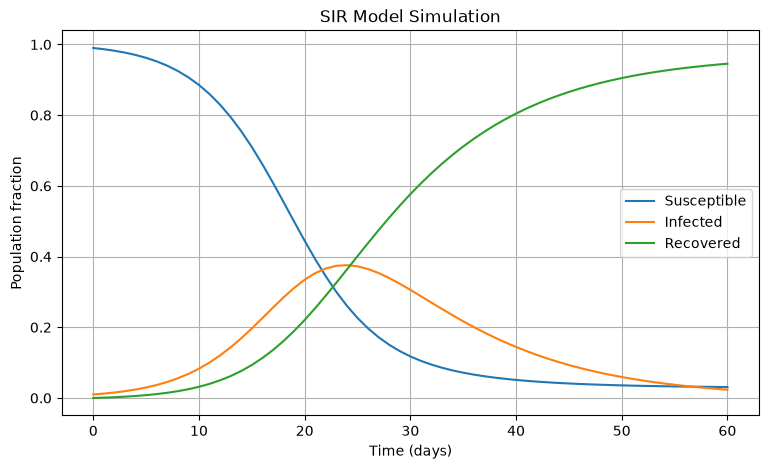

In [11]:
ts, Ss, Is, Rs = dm.SIR_model() # Calling the SIR_model from the `DynamicModelling` 

plt.figure(figsize=(9, 5))
plt.plot(ts, Ss, label="Susceptible")
plt.plot(ts, Is, label="Infected")
plt.plot(ts, Rs, label="Recovered")

plt.xlabel("Time (days)")
plt.ylabel("Population fraction")
plt.title("SIR Model Simulation")
plt.legend()
plt.grid()
plt.show()

#### Looking at the plot

The plot shows a correlation between the suspectibale, infected and recovered-trendline. The more people recover, the less people there are that are suspectible to catch the desease. We are looking at dummy-data here, so it is wrong to assume this conclusion to be realistic. But it is a nice way of experimenting with different models to look at their output. 

We can also plot a certain region alone using the SIR-model. We are looking at an example below. 

Looking at the dummy-data, we can see that the data is divided by regions. In this example we are curious about the north region.

Let's plot the graph.

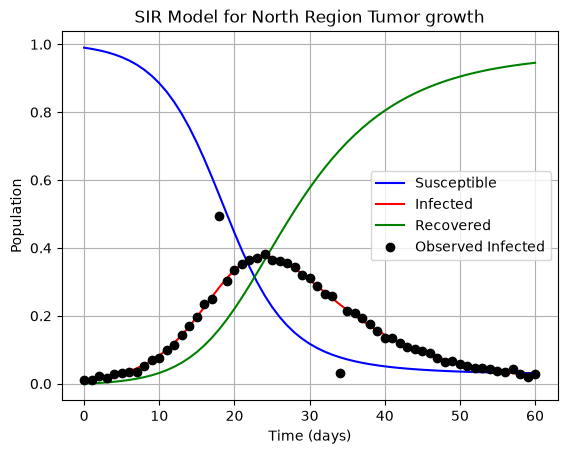

In [12]:
dm.plot_SIR(region="Region_North") # Calling north-region plot SIR

As you can see, this plot also contains the "real" data-values, shown in black. There are two visible outliers, but in general they do not need seem to influence the trendline. 

Showing you this example, we can conclude that there are many ways to implement your own parameters to models such as the SIR-model. 

### Workshop 2: ODE-solvers

We are going to compare different numerical methods for solving ordinary differential equations (ODEs). We apply Euler, Heun and Runge-Kutta to model tumor growth. 

#### Requirements

* Pandas, Numpy and matplotlib packages
* `main.py`
* `generated_data/tumorgroei_dummy_dataset.csv`

#### Setting the model up

We load the simulated tumor growth dataset and start the DynamicModelling class:



In [13]:
import pandas as pd # file reading and data manipulation
import main

data = pd.read_csv('generated_data/tumorgroei_dummy_dataset.csv') # generated data
dm = main.DynamicModelling(data) # starting the `DynamicModelling` class

### Running the ODE-solvers

We are using the code from the exponential growth model from the `main.py` file to compare the three numerical methods mentioned in the workshop 2 introduction. We are doing this for the different treatment groups. 

The code below calls the main for the heun, Runga Kutta and Euler method.

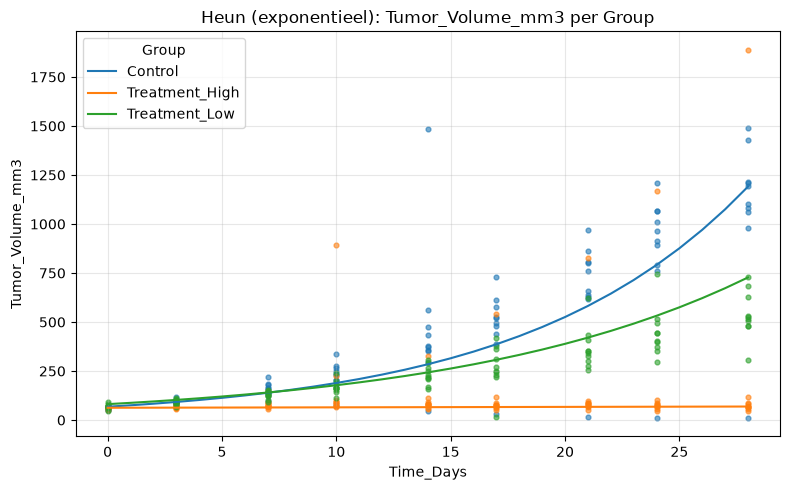

In [14]:
# Heun method
results_heun = dm.ODE_methods(
    model="Heun",
    groupby="Group",
    ground="Time_Days",
    references=["Tumor_Volume_mm3"],
    growth_model="exponentieel",
    plot=True
)

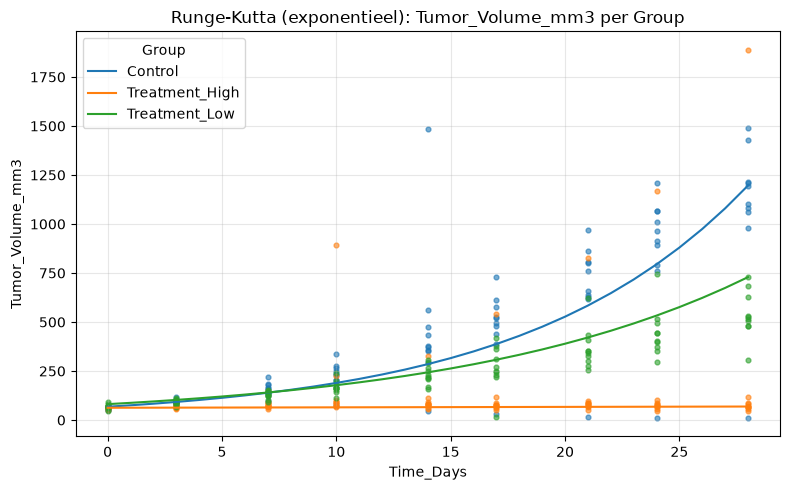

In [15]:
# Runge-Kutta method
results_rk = dm.ODE_methods(
    model="Runge-Kutta",
    groupby="Group",
    ground="Time_Days",
    references=["Tumor_Volume_mm3"],
    growth_model="exponentieel",
    plot=True
)

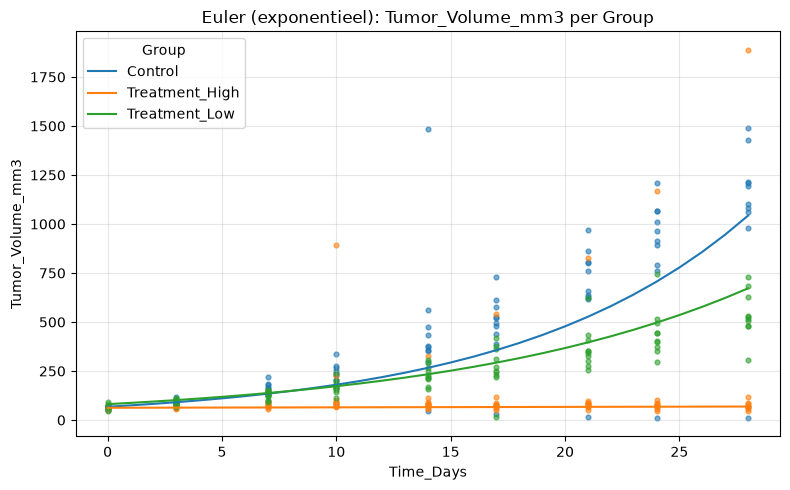

In [16]:
# Euler method
results_euler = dm.ODE_methods(
    model="Euler",
    groupby="Group",
    ground="Time_Days",
    references=["Tumor_Volume_mm3"],
    growth_model="exponentieel",
    plot=True
)

### Discussing the results

The three plots shown above show the predicted tumor growth using Euler, Heun and Runge-Kutta.

The control group shows clear exponential growth over time. The Treatment_Low group als shows tumor growth, but at a lower rate than Control. The Treatment_High group shows very small growth in the predicted trendline. 

The three numerical methods produce similar outcomes. However, some differences can be observed towards the end of the predictions. Euler produces slightly lower predicitions than Heun and RUnge-Kutta for the control and low treatment groups.

The experimental (generated) data points show signifcant variation within each treatment group. 

**Please note**

The methods show very similar results, but their predictions are not identical if you look at the fine details.

### Workshop 3: Optimization 

We are going to look at optimizing a real (non-generated) tumor growth model. We are using Random Search to find the growth parameter. This parameter finds deviations between the model and the data and makes it as small as possible. We are also trying to minimize the Mean Squared Error (MSE).

#### Requirements for this demo

* `main.py` with the `DynamicModelling` class
* input-file found under `generated_data/peerj-07-6983-s001.csv`
* `Pandas` and `Matplotlib`


#### Setup 

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import main
import importlib

importlib.reload(main) # reloads the main.py to ensure the latest version is used

data = pd.read_csv('generated_data/peerj-07-6983-s001.csv') # Reference can be found in the README.
dm = main.DynamicModelling(data) # Initializing the model

#### Running the model

We apply the exponential growth model to the tumor dataset. The differential equations are solved using the Runge-Kutta ODE-solver.

Random Search adjusts the model parameters to minimize the MSE for each treatment group (`TRT`).

Now it's time to run the model optimization.



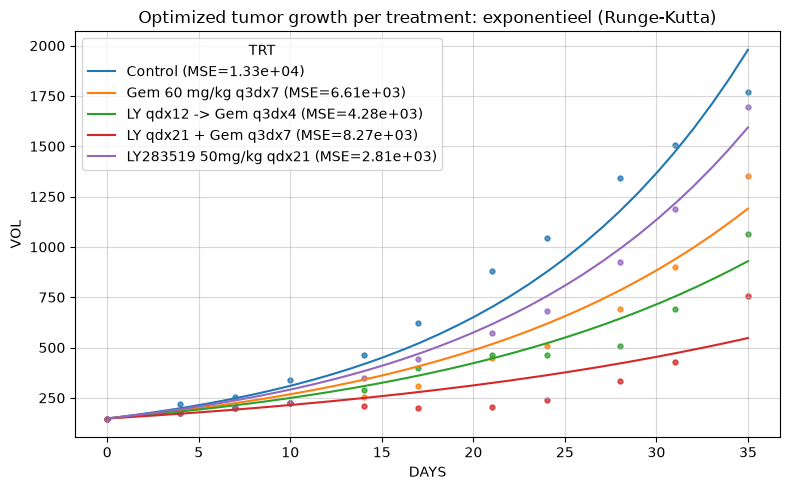

In [18]:
results = dm.optimization(
    model="exponentieel",
    method="Runge-Kutta",
    groupby="TRT",
    ground="DAYS",
    references=["VOL"],
    plot=True
)

### Results interpretation 

The optimization results show differences in tumor growth between treatment groups. The control group demonstartes the strongest tumor growth, while the LY QDX + Gem treatment show the lowest predicted tumor growth. 

Regarding model performance, the LY283... 50mg/kg treatment group has the lowest MSE. This indicates the best fit between observed data and the predicted exponential growth curve. The control group has the highest MSE.

These results show that a lower MSE does not necessarily mean a more effective treatment. MSE measures how accuratly the model describes the observed data, rather tgan the effectiveness of a treatment. 

Overall the exponential model provides a useful way to compare tumor growth patterns. However, further statistical analysis would be required to show real significance. 

### Workshop 4: Model comparison

Now we are going to compare different tumor growth models using statistical criteria. We use AIC, AICc and BIC to evaluate model fit. This is done while taking the number of model parameters into account.

#### Requirements for this model

* All previously mentioned packages and files. 
* `generated_data/peerj-07-6983-s001.csv`

#### Setup

For this demonstration we are using the **real** PeerJ tumor growth dataset from workshop 3. 

First we need to load the correct file.

In [19]:
import pandas as pd
import main

data = pd.read_csv("generated_data/peerj-07-6983-s001.csv")
dm = main.DynamicModelling(data)

### Running the model comparison

We compare six different tumor growth models using the Runge-Kutta method. The models are fitted independently for each treatment group. AIC, AICc and BIC are calculated to test their fit and complexity.

Now we are going to run the comparison using the `main.py` comparison method. 

In [20]:
# Compare different tumor growth models
comparison = dm.model_comparison(
    groupby="TRT",                 
    ground="DAYS",                
    references=["VOL"],            
    method="Runge-Kutta",          # Numerical method used to solve the ODEs
    models=[
        "lineair",
        "exponentieel",
        "mendelsohn",
        "exponentieel_afvlakkend",
        "logistisch",
        "gompertz"
    ],
    max_iter=2000,                 # Maximum number of optimization iterations
    patience=100                   # Stop after 100 iterations without improvement
)

# Display the results
print(comparison)

                           n   k           MSE          AIC         AICc  \
exponentieel             110   5   7047.734498   984.650765   985.227688   
gompertz                 110  10   6630.048607   987.930416   990.152638   
mendelsohn               110  10  10172.856448  1035.022615  1037.244837   
logistisch               110  10  11542.104838  1048.913261  1051.135483   
lineair                  110   5  26400.253678  1129.924179  1130.501102   
exponentieel_afvlakkend  110  10  26649.087415  1140.956120  1143.178343   

                                 BIC  
exponentieel              998.153166  
gompertz                 1014.935219  
mendelsohn               1062.027419  
logistisch               1075.918065  
lineair                  1143.426581  
exponentieel_afvlakkend  1167.960924  


### Reviewing the results

The model comparison shows that the exponential growth model provides the best overall fit among the six tested models. 

It achieves the lowest AIC (984.65), AICc (985.23) and BIC (998.15). The Gompertz model ranks second, followed by the Mendelsohn and logistic models.

The linear and exponential flattening models show higher information criterion values. This indicates a poorer fit compared to the other models. 

All models were evaluated using 110 observations. The results suggest that exponential growth describes the tumor growth dat better than the other models. 

### Conclusion

In this case study, we explored different ways to model biological processes and tumor growth data. We tested several ODE-solvers and compared six growth models. The exponential model performed best in comparison to the other models.